# متریک‌های ارزیابی Classification

## هدف
درک عمیق Confusion Matrix, Precision, Recall, F1, AUC.

## مفاهیم
- Confusion Matrix (TP, TN, FP, FN)
- Precision, Recall, F1
- چرا Accuracy گمراه‌کننده است
- AUC-ROC

## سؤال‌های مصاحبه‌ای
1. تفاوت Precision و Recall؟
2. چرا F1 از Accuracy بهتر است در داده نامتوازن؟
3. AUC-ROC چه می‌گوید؟

In [1]:
import numpy as np
import pandas as pd
from sklearn.metrics import (confusion_matrix, precision_score,
                             recall_score, f1_score, accuracy_score,
                             roc_auc_score, roc_curve)
import matplotlib.pyplot as plt

# مثال: ۱۰۰ بیمار، ۱۰ واقعاً بیمار
y_true = np.array([1]*10 + [0]*90)
# مدل: ۸ بیمار را درست، ۱۲ سالم را اشتباهاً بیمار گفت
y_pred = np.array([1]*8 + [0]*2 + [1]*12 + [0]*78)

cm = confusion_matrix(y_true, y_pred)
print("Confusion Matrix:")
print(cm)
print("\n           پیش‌بینی")
print("           سالم  بیمار")
print(f"واقعی سالم  {cm[0,0]:4d}  {cm[0,1]:4d}")
print(f"      بیمار  {cm[1,0]:4d}  {cm[1,1]:4d}")

Confusion Matrix:
[[78 12]
 [ 2  8]]

           پیش‌بینی
           سالم  بیمار
واقعی سالم    78    12
      بیمار     2     8


In [4]:
TP, TN, FP, FN = 8, 78, 12, 2

accuracy = (TP + TN) / (TP + TN + FP + FN)
precision = TP / (TP + FP)
recall = TP / (TP + FN)
f1 = 2 * (precision * recall) / (precision + recall)

print(f"Accuracy:  {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1:        {f1:.3f}")

Accuracy:  0.860
Precision: 0.400
Recall:    0.800
F1:        0.533


In [9]:
print("Accuracy:", accuracy_score(y_true, y_pred)*100)
print("Precision:", precision_score(y_true, y_pred)*100)
print("Recall:", recall_score(y_true, y_pred)*100)
print("F1:", f1_score(y_true, y_pred)*100)

Accuracy: 86.0
Precision: 40.0
Recall: 80.0
F1: 53.333333333333336


AUC: 0.973


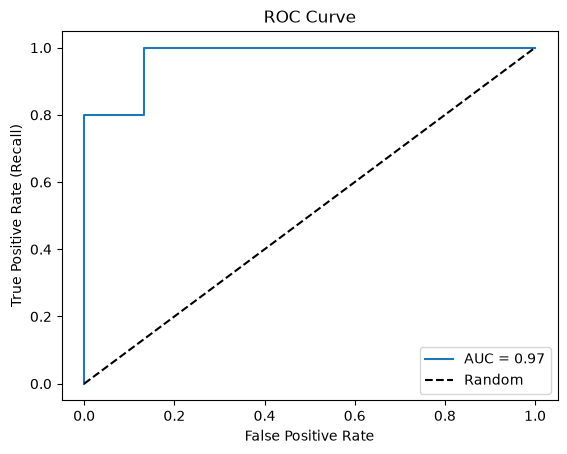

In [10]:
# برای AUC به احتمال نیاز داریم، نه فقط ۰/۱
y_proba = np.array([0.9]*8 + [0.3]*2 + [0.6]*12 + [0.2]*78)

auc = roc_auc_score(y_true, y_proba)
print(f"AUC: {auc:.3f}")

fpr, tpr, _ = roc_curve(y_true, y_proba)
plt.plot(fpr, tpr, label=f'AUC = {auc:.2f}')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve')
plt.legend()
plt.show()

In [11]:
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]
for t in thresholds:
    y_pred_t = (y_proba >= t).astype(int)
    p = precision_score(y_true, y_pred_t, zero_division=0)
    r = recall_score(y_true, y_pred_t, zero_division=0)
    f = f1_score(y_true, y_pred_t, zero_division=0)
    print(f"آستانه {t}: Precision={p:.2f}, Recall={r:.2f}, F1={f:.2f}")

آستانه 0.3: Precision=0.45, Recall=1.00, F1=0.62
آستانه 0.4: Precision=0.40, Recall=0.80, F1=0.53
آستانه 0.5: Precision=0.40, Recall=0.80, F1=0.53
آستانه 0.6: Precision=0.40, Recall=0.80, F1=0.53
آستانه 0.7: Precision=1.00, Recall=0.80, F1=0.89
